In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia import config
from energia.dataset import cargar_datos_modelo
from energia.entrenamiento import dispositivo, predecir
from energia.metricas import error_por_hora, naive_estacional
from energia.modelos import gru
from energia.optimizacion import experimento, etapa, mejor, historial, cargar_modelo
from energia.visualizacion import estilo, guardar_figura, curvas_aprendizaje, pronostico_vs_real

estilo()
RED = "gru"
print("torch", torch.__version__, "| dispositivo:", dispositivo())
datos = cargar_datos_modelo()

torch 2.5.1+cu124 | dispositivo: cuda


In [2]:
MODELO_FASE2 = {"oculto": 48, "capas": 2, "dropout": 0.15, "atencion": 32, "cabeza": 64}
ENTRENAMIENTO_FASE2 = {"optimizador": "adam", "lr": 1e-3, "epocas": 50, "batch": 256, "paciencia": 8, "clip": 1.0}

In [3]:
LR_INICIAL = {"sgd": 1e-2, "momentum": 1e-2, "nesterov": 1e-2, "adagrad": 1e-2,
              "rmsprop": 1e-3, "adam": 1e-3, "nadam": 1e-3, "adamax": 2e-3}

for opt, lr in LR_INICIAL.items():
    experimento(RED, "1_optimizador", opt, gru, datos, MODELO_FASE2,
                {**ENTRENAMIENTO_FASE2, "optimizador": opt, "lr": lr})

etapa(RED, "1_optimizador")

[1_optimizador] sgd (semilla 42): ya registrado, val_precio_MAPE_% = 24.86
[1_optimizador] momentum (semilla 42): ya registrado, val_precio_MAPE_% = 22.68
[1_optimizador] nesterov (semilla 42): ya registrado, val_precio_MAPE_% = 22.55
[1_optimizador] adagrad (semilla 42): ya registrado, val_precio_MAPE_% = 21.85
[1_optimizador] rmsprop (semilla 42): ya registrado, val_precio_MAPE_% = 23.15
[1_optimizador] adam (semilla 42): ya registrado, val_precio_MAPE_% = 24.53
[1_optimizador] nadam (semilla 42): ya registrado, val_precio_MAPE_% = 24.28
[1_optimizador] adamax (semilla 42): ya registrado, val_precio_MAPE_% = 25.52


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos
0,adagrad,42,21.847562,2.450724,100.037538,0.580411,0.137360,8,16,0.5
1,nesterov,42,22.554605,2.282923,96.845174,0.606763,0.133894,34,42,1.4
2,momentum,42,22.675971,2.242061,97.156488,0.604231,0.131820,49,50,1.6
3,rmsprop,42,23.153046,2.247542,98.403002,0.594010,0.129248,8,16,0.5
4,nadam,42,24.284046,2.201425,98.433463,0.593759,0.129816,6,14,0.5
5,adam,42,24.530214,2.352308,100.052148,0.580288,0.140529,9,17,0.6
6,sgd,42,24.859086,2.626632,99.014741,0.588947,0.159475,50,50,1.5
7,adamax,42,25.516007,2.326725,100.613018,0.575569,0.141592,13,21,0.7


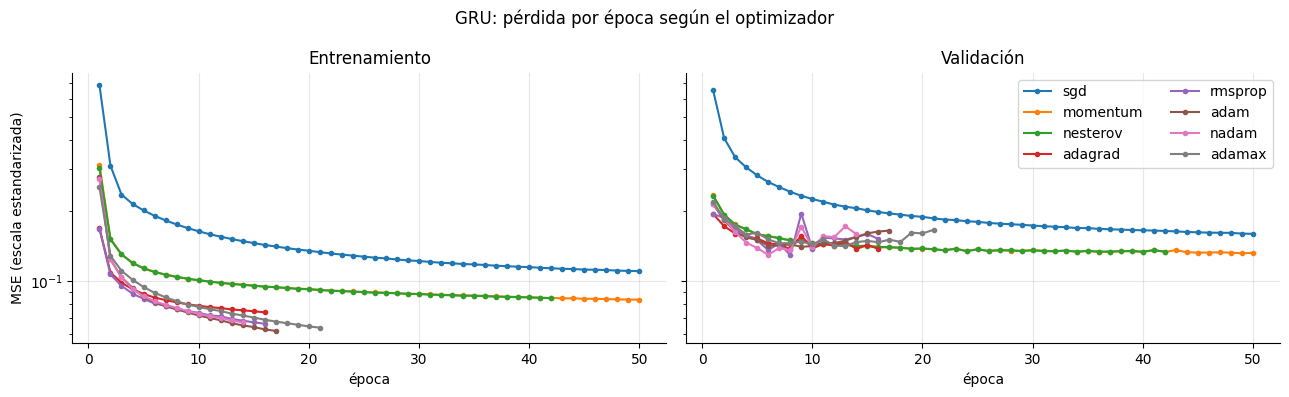

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for opt in LR_INICIAL:
    h = historial(RED, "1_optimizador", opt)
    axes[0].plot(h.index, h["train"], marker=".", label=opt)
    axes[1].plot(h.index, h["val"], marker=".", label=opt)
axes[0].set(title="Entrenamiento", xlabel="época", ylabel="MSE (escala estandarizada)", yscale="log")
axes[1].set(title="Validación", xlabel="época", yscale="log")
axes[1].legend(ncol=2)
fig.suptitle("GRU: pérdida por época según el optimizador")
fig.tight_layout()
guardar_figura(fig, "f3_01_gru_optimizadores")
plt.show()

In [5]:
E1 = mejor(RED, "1_optimizador")
OPT, LR = E1["nombre"], E1["hp_entrenamiento"]["lr"]
print("optimizador:", OPT, "| lr:", LR)

for lr in [LR, LR / 3]:
    for dropout in [0.15, 0.3]:
        for wd in [0.0, 1e-4]:
            experimento(RED, "2_regularizacion", f"lr{lr:.0e}_do{dropout}_wd{wd:.0e}", gru, datos,
                        {**MODELO_FASE2, "dropout": dropout},
                        {**ENTRENAMIENTO_FASE2, "optimizador": OPT, "lr": lr, "weight_decay": wd})

etapa(RED, "2_regularizacion")

optimizador: adagrad | lr: 0.01
[2_regularizacion] lr1e-02_do0.15_wd0e+00 (semilla 42): ya registrado, val_precio_MAPE_% = 21.85
[2_regularizacion] lr1e-02_do0.15_wd1e-04 (semilla 42): ya registrado, val_precio_MAPE_% = 23.00
[2_regularizacion] lr1e-02_do0.3_wd0e+00 (semilla 42): ya registrado, val_precio_MAPE_% = 23.49
[2_regularizacion] lr1e-02_do0.3_wd1e-04 (semilla 42): ya registrado, val_precio_MAPE_% = 22.86
[2_regularizacion] lr3e-03_do0.15_wd0e+00 (semilla 42): ya registrado, val_precio_MAPE_% = 24.33
[2_regularizacion] lr3e-03_do0.15_wd1e-04 (semilla 42): ya registrado, val_precio_MAPE_% = 23.77
[2_regularizacion] lr3e-03_do0.3_wd0e+00 (semilla 42): ya registrado, val_precio_MAPE_% = 23.80
[2_regularizacion] lr3e-03_do0.3_wd1e-04 (semilla 42): ya registrado, val_precio_MAPE_% = 24.05


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos
0,lr1e-02_do0.15_wd0e+00,42,21.847562,2.450724,100.037538,0.580411,0.137360,8,16,0.5
1,lr1e-02_do0.3_wd1e-04,42,22.862142,2.401042,97.504194,0.601393,0.135939,14,22,0.7
2,lr1e-02_do0.15_wd1e-04,42,23.003698,2.447581,97.942174,0.597804,0.138160,14,22,0.7
3,lr1e-02_do0.3_wd0e+00,42,23.485751,2.226798,97.777093,0.599159,0.129156,14,22,0.7
4,lr3e-03_do0.15_wd1e-04,42,23.769991,2.372594,97.861013,0.598470,0.137406,49,50,1.6
5,lr3e-03_do0.3_wd0e+00,42,23.801881,2.328602,97.863445,0.598450,0.132933,44,50,1.6
6,lr3e-03_do0.3_wd1e-04,42,24.050427,2.354809,97.611538,0.600515,0.135116,44,50,1.7
7,lr3e-03_do0.15_wd0e+00,42,24.332528,2.220879,98.750847,0.591135,0.130731,44,50,1.6


In [6]:
E2 = mejor(RED, "2_regularizacion")
M2, T2 = E2["hp_modelo"], E2["hp_entrenamiento"]
print(E2["nombre"], M2, T2)

NAIVE = {**M2, "corregir_naive": True}
VARIANTES = {
    "oculto64": ({**M2, "oculto": 64}, T2),
    "cabeza128": ({**M2, "cabeza": 128}, T2),
    "corregir_naive": (NAIVE, T2),
    "corregir_naive_adam": (NAIVE, {**T2, "optimizador": "adam", "lr": 1e-3}),
    "corregir_naive_150": (NAIVE, {**T2, "epocas": 150}),
}
for nombre, (hp_m, hp_t) in VARIANTES.items():
    experimento(RED, "3_arquitectura", nombre, gru, datos, hp_m, hp_t)

pd.concat([etapa(RED, "2_regularizacion").head(1).assign(etapa="2_regularizacion"),
           etapa(RED, "3_arquitectura").assign(etapa="3_arquitectura")], ignore_index=True)

lr1e-02_do0.15_wd0e+00 {'oculto': 48, 'capas': 2, 'dropout': 0.15, 'atencion': 32, 'cabeza': 64} {'optimizador': 'adagrad', 'lr': 0.01, 'epocas': 50, 'batch': 256, 'paciencia': 8, 'clip': 1.0, 'weight_decay': 0.0}
[3_arquitectura] oculto64 (semilla 42): ya registrado, val_precio_MAPE_% = 21.36
[3_arquitectura] cabeza128 (semilla 42): ya registrado, val_precio_MAPE_% = 21.33
[3_arquitectura] corregir_naive (semilla 42): ya registrado, val_precio_MAPE_% = 21.14
[3_arquitectura] corregir_naive_adam (semilla 42): ya registrado, val_precio_MAPE_% = 21.42
[3_arquitectura] corregir_naive_150 (semilla 42): ya registrado, val_precio_MAPE_% = 21.14


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos,etapa
0,lr1e-02_do0.15_wd0e+00,42,21.847562,2.450724,100.037538,0.580411,0.137360,8,16,0.5,2_regularizacion
1,corregir_naive,42,21.138242,2.049114,96.307514,0.611117,0.117423,8,16,0.5,3_arquitectura
2,corregir_naive_150,42,21.138242,2.049114,96.307514,0.611117,0.117423,8,16,0.5,3_arquitectura
3,cabeza128,42,21.334809,2.126876,97.337090,0.602758,0.121559,5,13,0.4,3_arquitectura
4,oculto64,42,21.359214,2.302223,99.237824,0.587092,0.130045,10,18,0.7,3_arquitectura
5,corregir_naive_adam,42,21.424028,1.974994,96.963092,0.605805,0.115687,7,15,0.5,3_arquitectura


In [7]:
FINAL = mejor(RED, ["2_regularizacion", "3_arquitectura"])
MF, TF = FINAL["hp_modelo"], FINAL["hp_entrenamiento"]
NOMBRE = FINAL["nombre"]
print(FINAL["etapa"], NOMBRE)
print(MF)
print(TF)

SEMILLAS = [42, 7, 2026]
for s in SEMILLAS:
    experimento(RED, "4_final", NOMBRE, gru, datos, MF, TF, semilla=s, prueba=True, guardar=True)

final = etapa(RED, "4_final").query("nombre == @NOMBRE")
final

3_arquitectura corregir_naive
{'oculto': 48, 'capas': 2, 'dropout': 0.15, 'atencion': 32, 'cabeza': 64, 'corregir_naive': True}
{'optimizador': 'adagrad', 'lr': 0.01, 'epocas': 50, 'batch': 256, 'paciencia': 8, 'clip': 1.0, 'weight_decay': 0.0}
[4_final] corregir_naive (semilla 42): ya registrado, val_precio_MAPE_% = 21.14
[4_final] corregir_naive (semilla 7): ya registrado, val_precio_MAPE_% = 20.04
[4_final] corregir_naive (semilla 2026): ya registrado, val_precio_MAPE_% = 21.54


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos,test_demanda_MAE,test_precio_MAE,test_demanda_RMSE,test_precio_RMSE,test_demanda_MAPE_%,test_precio_MAPE_%,test_demanda_R2,test_precio_R2
0,corregir_naive,7,20.037983,2.020844,97.101449,0.604679,0.117496,12,20,0.7,66210.997343,61.534366,91109.760897,102.560499,2.200467,14.604981,0.896376,0.898698
1,corregir_naive,42,21.138242,2.049114,96.307514,0.611117,0.117423,8,16,0.5,71598.338224,59.276283,96736.696621,100.381774,2.390087,14.574018,0.883182,0.902957
2,corregir_naive,2026,21.538847,2.051624,96.643331,0.608401,0.122810,17,25,0.8,69660.005147,77.253795,94384.988081,120.666355,2.312765,16.743251,0.888792,0.859774


In [8]:
fase2 = pd.read_csv(config.RESULTADOS / "fase2" / RED / "metricas.csv", index_col=[0, 1])
filas = {}
for split in ["val", "test"]:
    for c in ["demanda_MAPE_%", "precio_MAPE_%", "precio_RMSE", "precio_R2"]:
        filas[(split, c)] = {
            "GRU fase 2": fase2.loc[(RED, split), c],
            "GRU fase 3 (media)": final[f"{split}_{c}"].mean(),
            "GRU fase 3 (desv.)": final[f"{split}_{c}"].std(),
            "naive m=24": fase2.loc[("naive_m24", split), c],
            "naive m=168": fase2.loc[("naive_m168", split), c],
        }
comparacion = pd.DataFrame(filas).T.round(3)
comparacion.to_csv(config.RESULTADOS / "fase3" / RED / "comparacion_final.csv")
comparacion

GRU fase 2  GRU fase 3 (media)  GRU fase 3 (desv.)  \
val  demanda_MAPE_%       2.409               2.041               0.017   
     precio_MAPE_%       23.551              20.905               0.777   
     precio_RMSE         99.808              96.684               0.399   
     precio_R2            0.582               0.608               0.003   
test demanda_MAPE_%       2.589               2.301               0.095   
     precio_MAPE_%       16.386              15.307               1.244   
     precio_RMSE        105.631             107.870              11.136   
     precio_R2            0.893               0.887               0.024   

                     naive m=24  naive m=168  
val  demanda_MAPE_%       6.719        3.833  
     precio_MAPE_%       20.337       37.449  
     precio_RMSE        111.795      136.077  
     precio_R2            0.476        0.224  
test demanda_MAPE_%       6.671        4.060  
     precio_MAPE_%       14.863       34.665  
     precio_RMSE        111.123      182.249  
     precio_R2            0.881        0.680

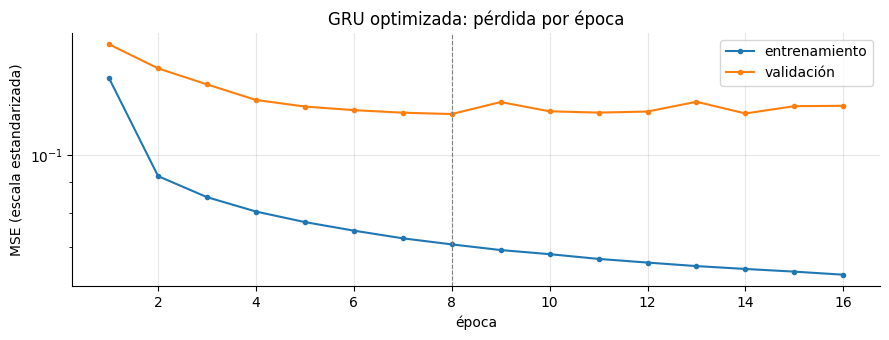

In [9]:
fig = curvas_aprendizaje(historial(RED, "4_final", NOMBRE, SEMILLAS[0]), "GRU optimizada: pérdida por época")
guardar_figura(fig, "f3_02_gru_curvas")
plt.show()

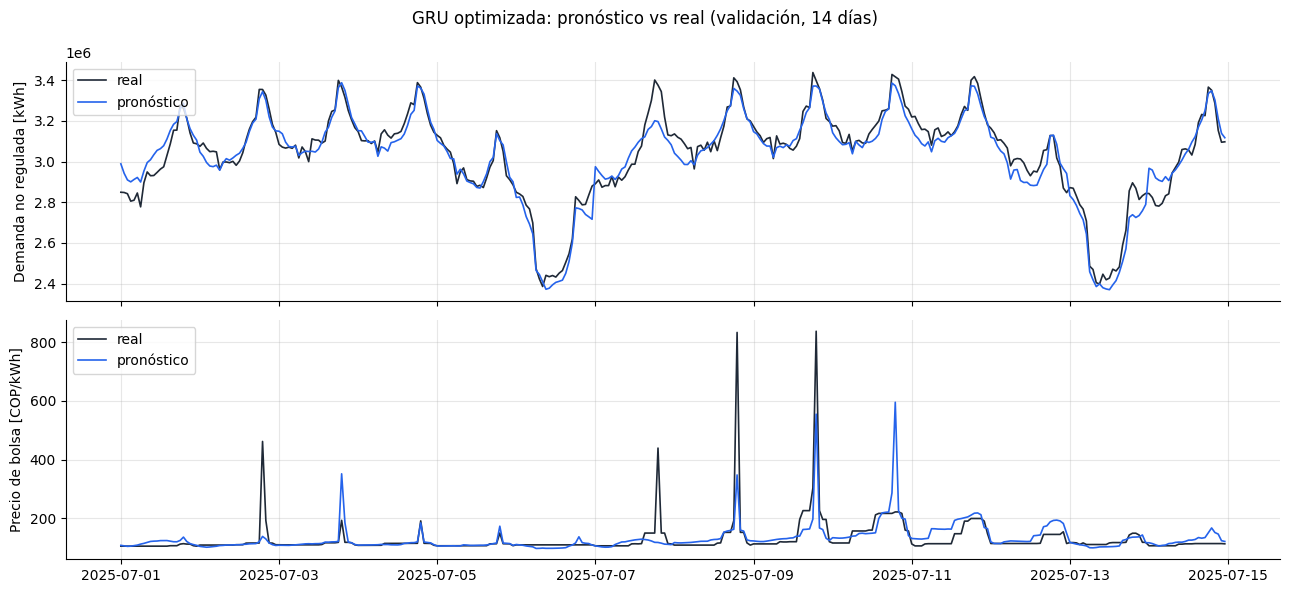

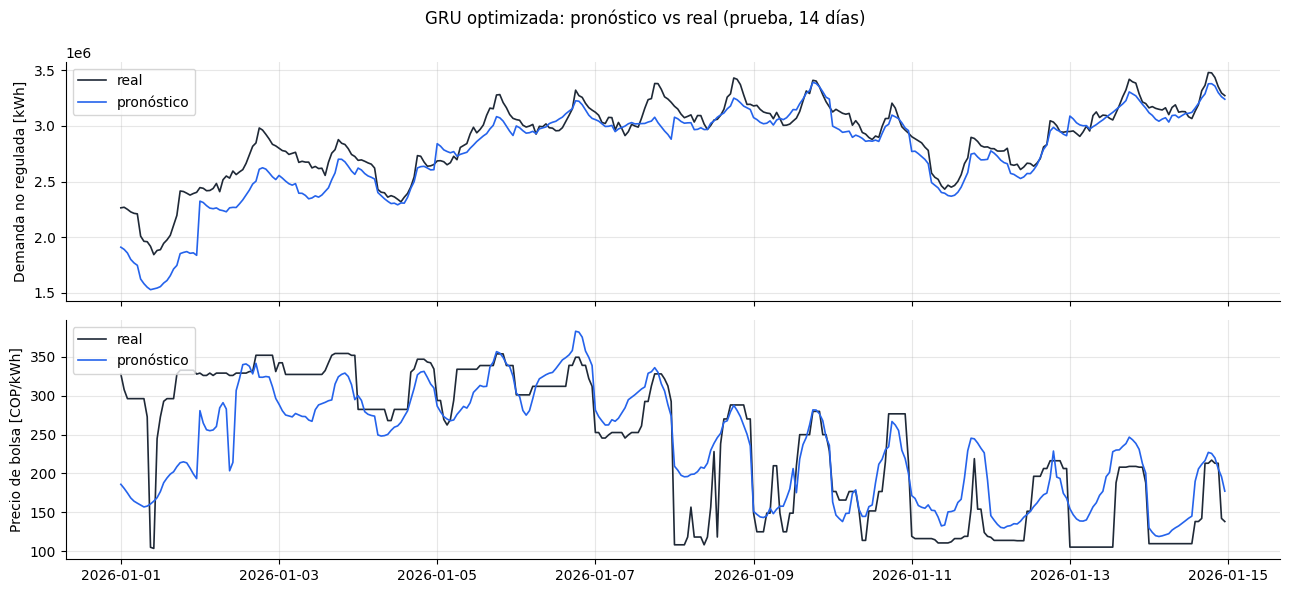

In [10]:
modelo = cargar_modelo(RED, "4_final", NOMBRE, gru, datos, semilla=SEMILLAS[0])
predicciones = {s: predecir(modelo, datos, s) for s in ["val", "test"]}

fig = pronostico_vs_real(datos, predicciones["val"], "val", dias=14, titulo="GRU optimizada: pronóstico vs real (validación, 14 días)")
guardar_figura(fig, "f3_03_gru_pronostico_val")
plt.show()

fig = pronostico_vs_real(datos, predicciones["test"], "test", dias=14, titulo="GRU optimizada: pronóstico vs real (prueba, 14 días)")
guardar_figura(fig, "f3_04_gru_pronostico_test")
plt.show()

C:\Users\SARA ISABEL\AppData\Local\Temp\ipykernel_32980\3916200077.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  paquete = torch.load(config.MODELOS / "gru.pt", map_lo

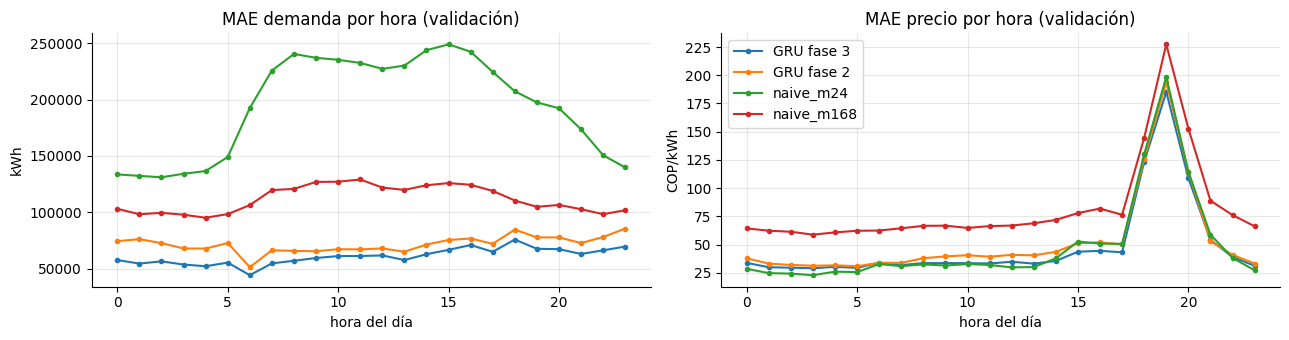

In [11]:
paquete = torch.load(config.MODELOS / "gru.pt", map_location="cpu")
modelo_f2 = gru.construir(datos, **{k: v for k, v in paquete["hiperparametros"].items() if k in gru.HIPERPARAMETROS})
modelo_f2.load_state_dict(paquete["estado"])

y_val = datos.y_original("val")
errores = {
    "GRU fase 3": error_por_hora(y_val, predicciones["val"]),
    "GRU fase 2": error_por_hora(y_val, predecir(modelo_f2, datos, "val")),
    "naive_m24": error_por_hora(y_val, naive_estacional(datos, "val", m=24)),
    "naive_m168": error_por_hora(y_val, naive_estacional(datos, "val", m=168)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre, e in errores.items():
    axes[0].plot(e.index - 1, e["demanda"], marker=".", label=nombre)
    axes[1].plot(e.index - 1, e["precio"], marker=".", label=nombre)
axes[0].set(title="MAE demanda por hora (validación)", xlabel="hora del día", ylabel="kWh")
axes[1].set(title="MAE precio por hora (validación)", xlabel="hora del día", ylabel="COP/kWh")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "f3_05_gru_error_por_hora")
plt.show()